# Which volatility model warns best? Model comparison on SPY, COVID-19 and the 2022 bear market

Every model below was trained only on data **before** its event cutoff, frozen, and then forecast
day by day with live inputs. Every model is scored from the same forecast files
(`data/processed/forecasts/`).

| Family | Inputs | Notes |
|---|---|---|
| GARCH | close-to-close returns | GARCH(1,1)-t, scaled to the RTH-RV level |
| HAR | log RV d/w/m (+ RS⁻, signed jump for `ext`) | OLS, smearing |
| XGB-linear / XGB-tree | same as HAR | Teller et al. (2022) search space, 100 TPE trials |
| HARNet | raw daily RV (+ RS⁻, ΔJ²) | PyTorch port, QLIKE, OLS-HAR init |
| LSTM | raw daily log RV (+ log RS⁻, jump) over a tuned 22–126-day lookback | control for "plain recurrence" |
| Mamba | same as LSTM | selective state-space (Gu & Dao 2023), trained on the AMD GPU |

**Three questions**

1. **COVID (fast crash):** who signalled first, and who said "this is going to continue" after the first drop?
2. **2022 (slow bear market):** who tracked the drawn-out decline best?
3. **Accuracy or alarm-happiness?** Did the models that looked good there forecast *accurately*,
   or do they simply raise alarms often? We judge alarms against realized stress on every
   out-of-sample day, including a **calm window** after each event (COVID model: 2020-07 → 2021-09;
   2022 model: 2023-04 → 2025-03).

**Measures** (`volforecast/evaluation.py`)

- **lift** = forecast variance ÷ the *normal* variance level, meaning the long-run mean RV of the training sample
  (≈ 14% annualized vol for both events). An **alarm** is lift ≥ τ, and **realized stress** is realized variance ≥ τ × normal.
  τ = 2 (variance double normal, ≈ 20% vol) is the headline threshold.
  The originally planned baseline, each model's own last 63 pre-cutoff days, is shown as a secondary view. It is degenerate
  for 2022 because Jul–Sep 2021 was unusually calm (≈ 8% vol), which makes every later day look like an alarm.
- **escalation** = forecast of the next h days ÷ RV over the last 5 days. Above 1 means the model expects things to get worse.
- **coverage** = forecast ÷ realized (forward). 1 = right level; below 1 = under-prediction.
- **Peirce skill** = hit rate − false-alarm rate. A model that always alarms scores 0, however many crashes it "catches".

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from IPython.display import display
from volforecast import adapters, evaluation as E, evaluation_plots as P
from volforecast.config import load_config, resolve_path, PROJECT_ROOT

pd.set_option("display.precision", 3); pd.set_option("display.width", 160)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9})
cfg = load_config()
features = adapters.load_features()
splits = {e: adapters.load_split(e) for e in ("covid", "bear2022")}
df = E.add_escalation(E.load_forecasts(basis="longrun", features=features), features)
df_tail = E.load_forecasts(basis="tail", features=features)
print({e: f"normal = {np.sqrt(252 * v) * 100:.1f}% ann. vol" for e, v in E.longrun_rv(features).items()})
out_dir = PROJECT_ROOT / "reports" / "eval"; out_dir.mkdir(parents=True, exist_ok=True)
print(df.groupby(["event", "family"])["model"].nunique().unstack(0))

{'covid': 'normal = 14.0% ann. vol', 'bear2022': 'normal = 14.6% ann. vol'}
event       bear2022  covid
family                     
GARCH            3.0    3.0
HAR              6.0    6.0
HARNet           6.0    6.0
LSTM             6.0    6.0
Mamba            NaN    6.0
XGB-linear       6.0    6.0
XGB-tree         6.0    6.0


## 1. Training metrics

Validation-block scores of each model's **train-only** fit, the setting that picked its
hyperparameters, iterations or epochs. Lower QLIKE is better, and the random walk (RW) is the benchmark.
The 2022 models validate on 2021-01 → 2021-09, a calm stretch; COVID is in their training data (§7).

In [2]:
train = E.training_summary()
train.to_csv(out_dir / "training_summary.csv", index=False)
pivot = train.pivot_table(index=["family", "model"], columns=["event", "h"], values="val_qlike")
rw = train.groupby(["event", "h"])["val_qlike_rw"].first().rename(("RW", "random walk")).to_frame().T
rw.columns = pd.MultiIndex.from_tuples(rw.columns)
display((pd.concat([pivot, rw])).style.format("{:.3f}").background_gradient(axis=0, cmap="Greens_r")
        .set_caption("Validation QLIKE (lower is better)"))

In [3]:
t = train.groupby("family")["train_seconds"].agg(["count", "sum", "median"]).rename(
    columns={"count": "cells", "sum": "total s", "median": "median s / cell"})
display(t.loc[[f for f in E.FAMILY_ORDER if f in t.index]].style.format("{:.1f}", subset=["total s", "median s / cell"]))

,cells,total s,median s / cell
family,,,
GARCH,6,2.1,0.4
HAR,12,0.4,0.0
XGB-linear,12,209.3,17.4
XGB-tree,12,240.9,20.5
HARNet,12,1461.6,66.6
LSTM,12,1068.1,87.4
Mamba,12,2031.3,157.3


## 2. Out-of-sample accuracy by window

Mean QLIKE per window, out of sample (the frozen model's live forecasts). `pre_event`/`event`/`post_event` are
the drawdown windows; `calm` is the quiet stretch afterwards.

In [4]:
acc = E.accuracy_table(df)
acc.to_csv(out_dir / "accuracy_by_window.csv", index=False)
for event in ("covid", "bear2022"):
    t = acc[acc["event"] == event].pivot_table(index=["family", "fs"], columns=["h", "sample"], values="qlike")
    t = t.reindex(columns=pd.MultiIndex.from_product([[1, 5, 22], E.OOS]), fill_value=np.nan)
    display(t.style.format("{:.3f}").background_gradient(axis=0, cmap="Greens_r")
            .set_caption(f"{event}: QLIKE by horizon and window (lower is better)"))

## 3. COVID-19 crash (fast)

Peak 2020-02-19, trough 2020-03-23. Models were frozen on 2019-12-31.
For h = 22, pre-peak *realized* targets already contain crash days, so judge the run-up by the
forecast's own movement (lift), not by forecast-vs-realized loss.

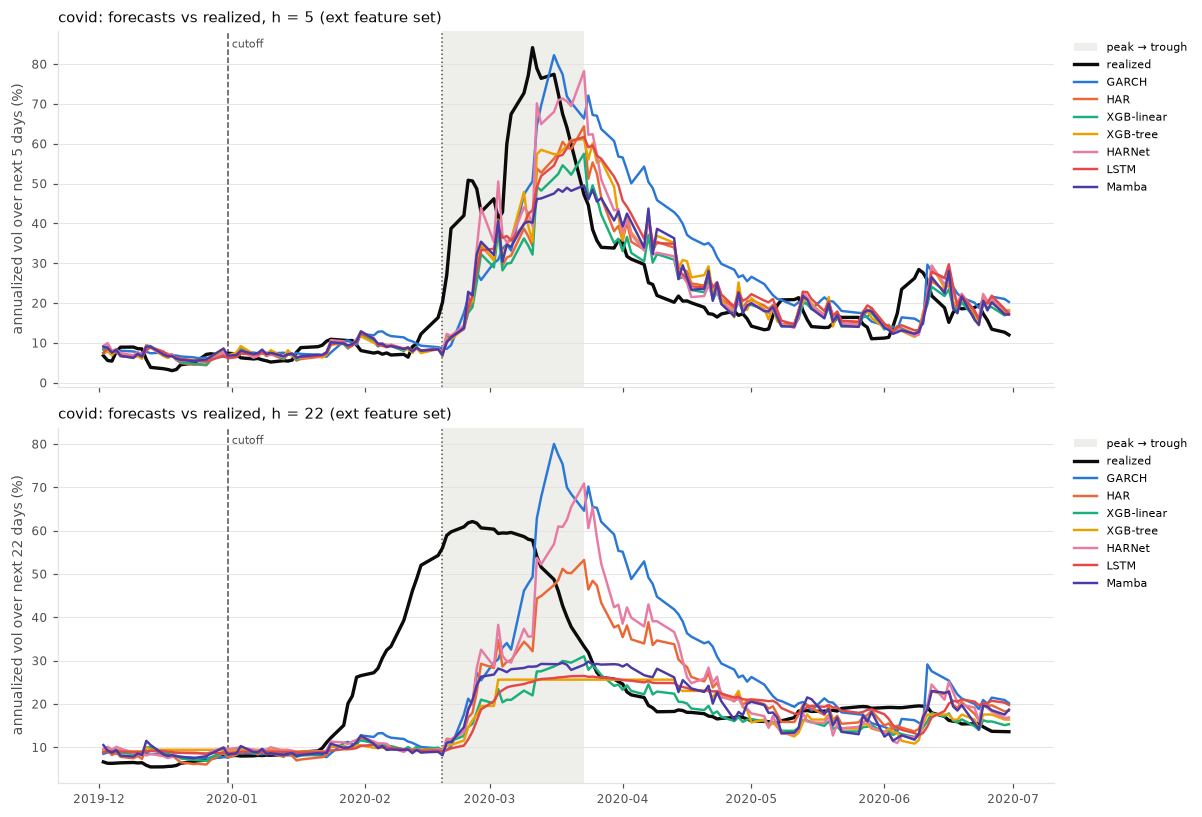

In [5]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
for ax, h in zip(axes, (5, 22)):
    P.plot_forecasts(df, "covid", h, "2019-12-01", "2020-06-30", splits["covid"], ax=ax)
fig.tight_layout(); fig.savefig(out_dir / "covid_forecasts.png", dpi=150)

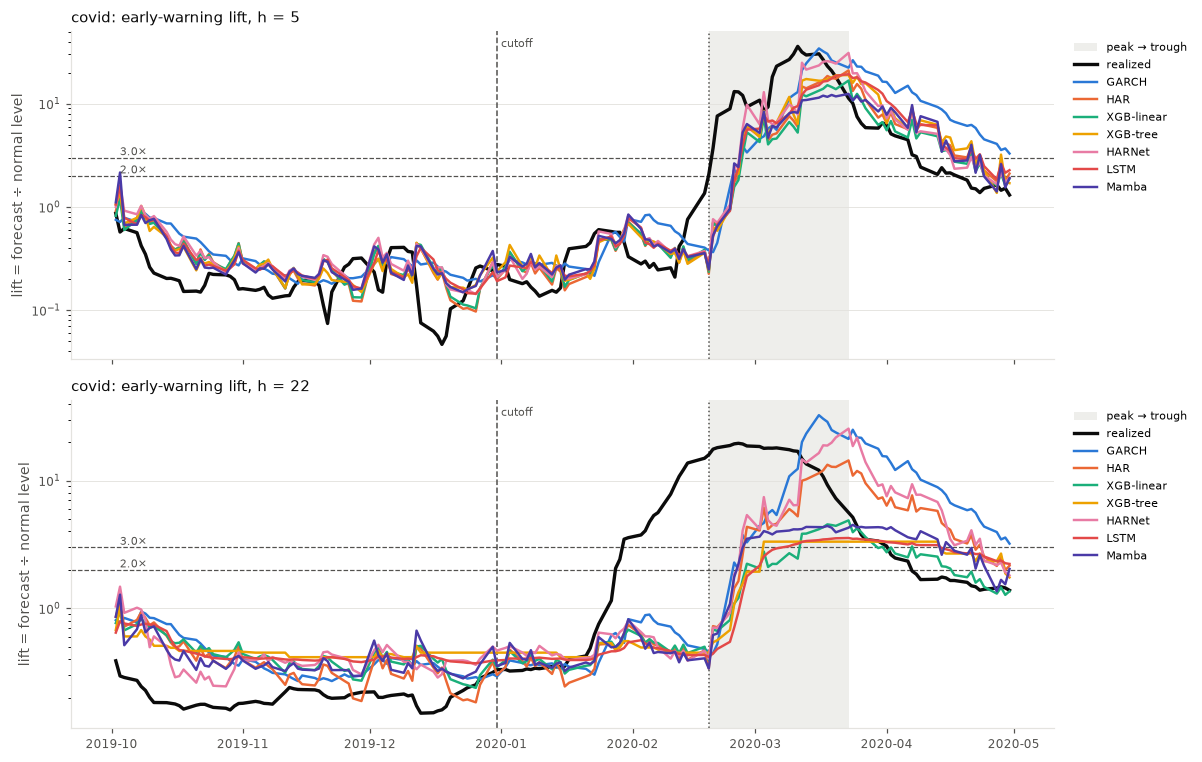

In [6]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, h in zip(axes, (5, 22)):
    P.plot_lift(df, "covid", h, "2019-10-01", "2020-04-30", splits["covid"], thresholds=(2.0, 3.0), ax=ax)
fig.tight_layout(); fig.savefig(out_dir / "covid_lift.png", dpi=150)

### 3a. Early warning: when did each model's forecast cross 1.5× / 2× / 3× normal?

`lead_days` = trading days **before** the peak (negative = after the peak). Searched from the cutoff to the trough.

In [7]:
lt = E.lead_times(df)
lt.to_csv(out_dir / "lead_times.csv", index=False)
cols = ["family", "fs", "h", "first_1.5x", "lead_days_1.5x", "first_2.0x", "lead_days_2.0x",
        "first_3.0x", "lead_days_3.0x", "max_lift_to_trough"]
display(lt[(lt["event"] == "covid") & lt["fs"].isin(["ext", "-"])].sort_values(["h", "family"])[cols]
        .set_index(["h", "family", "fs"]))
# Secondary view: lift against each model's own last 63 pre-cutoff days (the originally planned baseline)
lt_tail = E.lead_times(df_tail)
lt_tail.to_csv(out_dir / "lead_times_tail_baseline.csv", index=False)
display(lt_tail[(lt_tail["event"] == "covid") & lt_tail["fs"].isin(["ext", "-"])].sort_values(["h", "family"])
        [cols[:7]].set_index(["h", "family", "fs"]).style.set_caption("Own-tail baseline (secondary)"))

first_1.5x  lead_days_1.5x  first_2.0x  lead_days_2.0x  first_3.0x  lead_days_3.0x  max_lift_to_trough
h  family     fs                                                                                                         
1  GARCH      -    2020-02-24            -3.0  2020-02-25            -4.0  2020-02-27            -6.0              34.799
   HAR        ext  2020-02-25            -4.0  2020-02-25            -4.0  2020-02-27            -6.0              26.925
   HARNet     ext  2020-02-25            -4.0  2020-02-25            -4.0  2020-02-27            -6.0              31.522
   LSTM       ext  2020-02-25            -4.0  2020-02-25            -4.0  2020-02-27            -6.0              22.441
   Mamba      ext  2020-02-25            -4.0  2020-02-25            -4.0  2020-02-25            -4.0              16.034
   XGB-linear ext  2020-02-25            -4.0  2020-02-25            -4.0  2020-02-27            -6.0              26.659
   XGB-tree   ext  2020-02-25            -4.0  2020-02-25            -4.0  2020-02-27            -6.0              22.859
5  GARCH      -    2020-02-24            -3.0  2020-02-25            -4.0  2020-02-27            -6.0              34.348
   HAR        ext  2020-02-25            -4.0  2020-02-27            -6.0  2020-02-27            -6.0              21.048
   HARNet     ext  2020-02-25            -4.0  2020-02-25            -4.0  2020-02-27            -6.0              31.082
   LSTM       ext  2020-02-25            -4.0  2020-02-26            -5.0  2020-02-27            -6.0              19.340
   Mamba      ext  2020-02-25            -4.0  2020-02-25            -4.0  2020-02-27            -6.0              12.465
   XGB-linear ext  2020-02-25            -4.0  2020-02-27            -6.0  2020-02-27            -6.0              16.787
   XGB-tree   ext  2020-02-25            -4.0  2020-02-25            -4.0  2020-02-27            -6.0              18.964
22 GARCH      -    2020-02-24            -3.0  2020-02-25            -4.0  2020-02-27            -6.0              32.520
   HAR        ext  2020-02-26            -5.0  2020-02-27            -6.0  2020-02-28            -7.0              14.386
   HARNet     ext  2020-02-25            -4.0  2020-02-26            -5.0  2020-02-27            -6.0              25.526
   LSTM       ext  2020-02-28            -7.0  2020-03-02            -8.0  2020-03-09           -13.0               3.559
   Mamba      ext  2020-02-25            -4.0  2020-02-26            -5.0  2020-02-28            -7.0               4.418
   XGB-linear ext  2020-02-27            -6.0  2020-02-28            -7.0  2020-03-12           -16.0               4.887
   XGB-tree   ext  2020-02-27            -6.0  2020-03-03            -9.0  2020-03-03            -9.0               3.330

### 3b. Did the model say "this will continue" after the first drop?

The first 10 event days (2020-02-20 → 03-04): the market had fallen sharply, but most of the realized
volatility was still ahead (it peaked in mid-March).

- **escalation** > 1: the forecast for the next h days sits above the last 5 days' realized level, so the model expects worse to come.
- **coverage**: share of the coming realized variance the forecast anticipated.
- **shortfall**: cumulative realized − forecast variance over those days. Smaller is better.

ValueError: Unknown format code 'g' for object of type 'str'

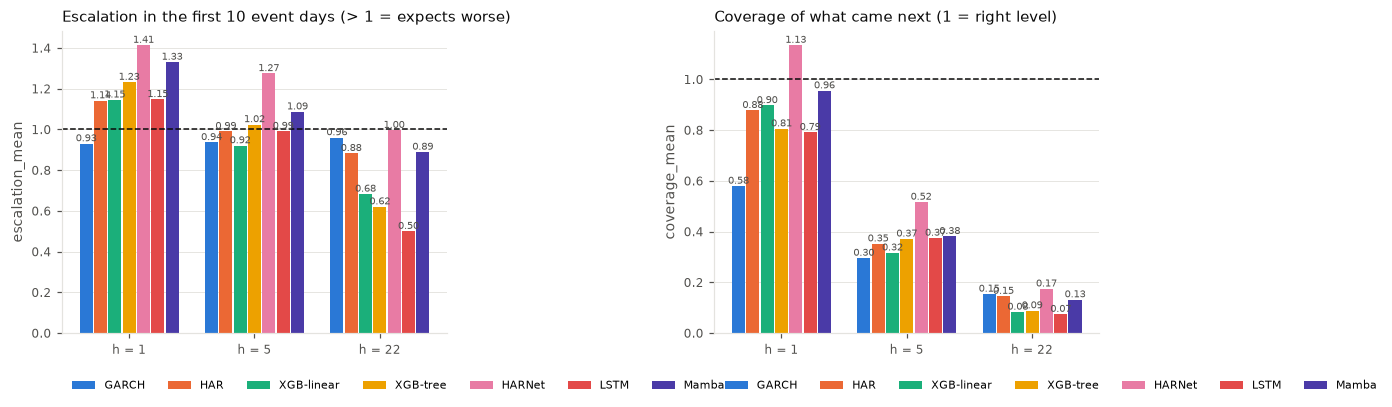

In [8]:
onset = E.onset_table(df, "covid", n_days=10)
onset.to_csv(out_dir / "covid_onset.csv", index=False)
display(onset[onset["fs"].isin(["ext", "-"])].sort_values(["h", "coverage_mean"], ascending=[True, False])
        .set_index(["h", "family"]).drop(columns=["fs"]).style.format("{:.3g}"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
P.bar_by_family(onset, "escalation_mean", ax=axes[0], ref=1.0, title="Escalation in the first 10 event days (> 1 = expects worse)")
P.bar_by_family(onset, "coverage_mean", ax=axes[1], ref=1.0, title="Coverage of what came next (1 = right level)")
fig.tight_layout(); fig.savefig(out_dir / "covid_onset.png", dpi=150)

## 4. 2022 bear market (slow)

Peak 2022-01-03, trough 2022-10-12. Models were frozen on 2021-09-30. They train through 2020-12 (COVID included) and validate on 2021-01 → 2021-09 (see §7). Volatility in 2022 was
elevated but never spiked like 2020, so the test is **staying on the right level for nine months**.

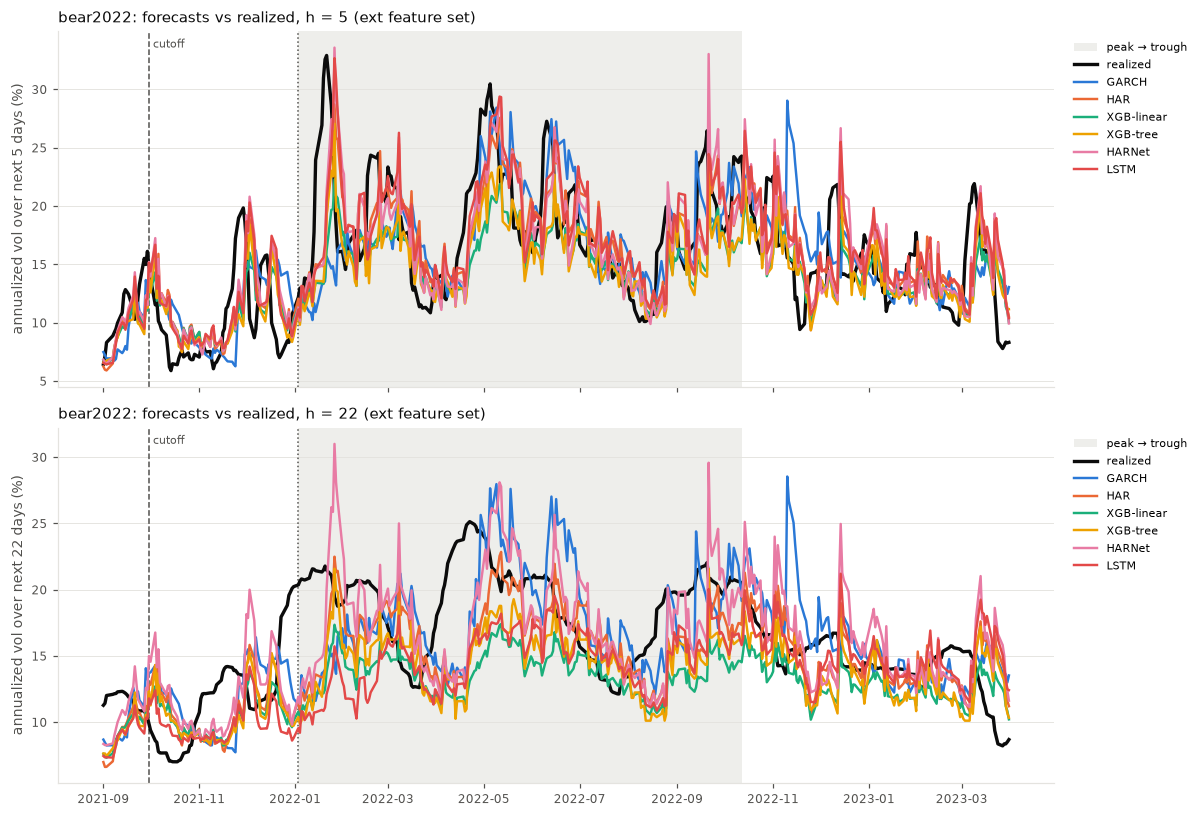

In [9]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7.5), sharex=True)
for ax, h in zip(axes, (5, 22)):
    P.plot_forecasts(df, "bear2022", h, "2021-09-01", "2023-03-31", splits["bear2022"], ax=ax)
fig.tight_layout(); fig.savefig(out_dir / "bear2022_forecasts.png", dpi=150)

first_1.5x  lead_days_1.5x  first_2.0x  lead_days_2.0x  first_3.0x  lead_days_3.0x  max_lift_to_trough
h  family     fs                                                                                                         
1  GARCH      -    2022-02-03           -22.0  2022-03-09           -45.0  2022-04-29           -81.0               3.812
   HAR        ext  2021-12-01            22.0  2022-01-21           -13.0  2022-01-24           -14.0               4.927
   HARNet     ext  2021-12-01            22.0  2021-12-03            20.0  2022-01-24           -14.0               5.934
   LSTM       ext  2021-12-01            22.0  2021-12-03            20.0  2022-01-24           -14.0               6.192
   XGB-linear ext  2021-12-03            20.0  2022-01-24           -14.0  2022-01-24           -14.0               4.679
   XGB-tree   ext  2021-12-01            22.0  2021-12-01            22.0  2022-01-24           -14.0               7.355
5  GARCH      -    2022-02-03           -22.0  2022-03-09           -45.0  2022-04-29           -81.0               3.781
   HAR        ext  2021-12-03            20.0  2022-01-24           -14.0  2022-01-26           -16.0               3.857
   HARNet     ext  2021-12-01            22.0  2021-12-03            20.0  2022-01-24           -14.0               5.274
   LSTM       ext  2021-12-01            22.0  2022-01-24           -14.0  2022-01-25           -15.0               4.993
   XGB-linear ext  2022-01-24           -14.0  2022-01-26           -16.0        None             NaN               2.323
   XGB-tree   ext  2021-12-03            20.0  2022-01-24           -14.0  2022-01-26           -16.0               3.422
22 GARCH      -    2022-02-03           -22.0  2022-03-09           -45.0  2022-04-29           -81.0               3.658
   HAR        ext  2022-01-24           -14.0  2022-01-26           -16.0        None             NaN               2.442
   HARNet     ext  2021-12-01            22.0  2022-01-24           -14.0  2022-01-24           -14.0               4.495
   LSTM       ext  2022-03-08           -44.0        None             NaN        None             NaN               1.880
   XGB-linear ext        None             NaN        None             NaN        None             NaN               1.418
   XGB-tree   ext  2022-01-24           -14.0  2022-01-26           -16.0        None             NaN               2.178

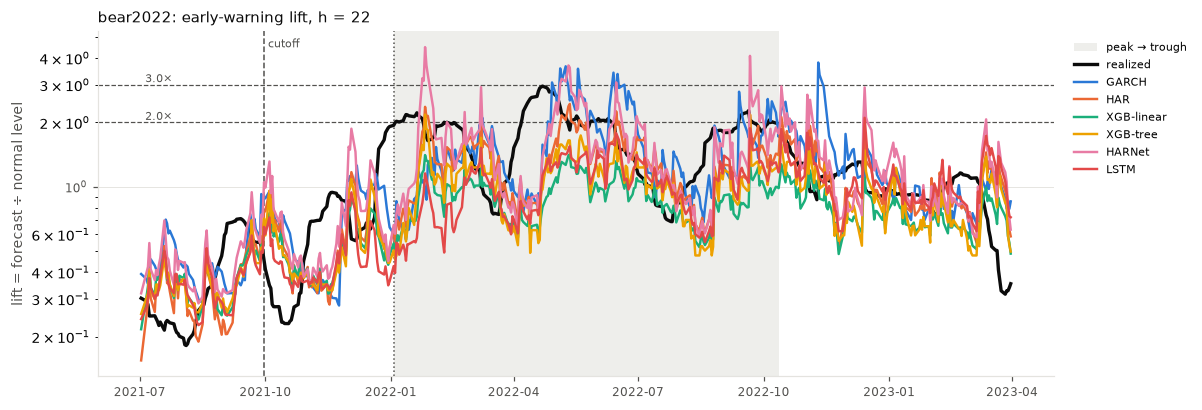

In [10]:
fig, ax = plt.subplots(figsize=(11, 3.8))
P.plot_lift(df, "bear2022", 22, "2021-07-01", "2023-03-31", splits["bear2022"], thresholds=(2.0, 3.0), ax=ax)
fig.tight_layout(); fig.savefig(out_dir / "bear2022_lift.png", dpi=150)
display(lt[(lt["event"] == "bear2022") & lt["fs"].isin(["ext", "-"])].sort_values(["h", "family"])[cols]
        .set_index(["h", "family", "fs"]))

ValueError: Unknown format code 'f' for object of type 'str'

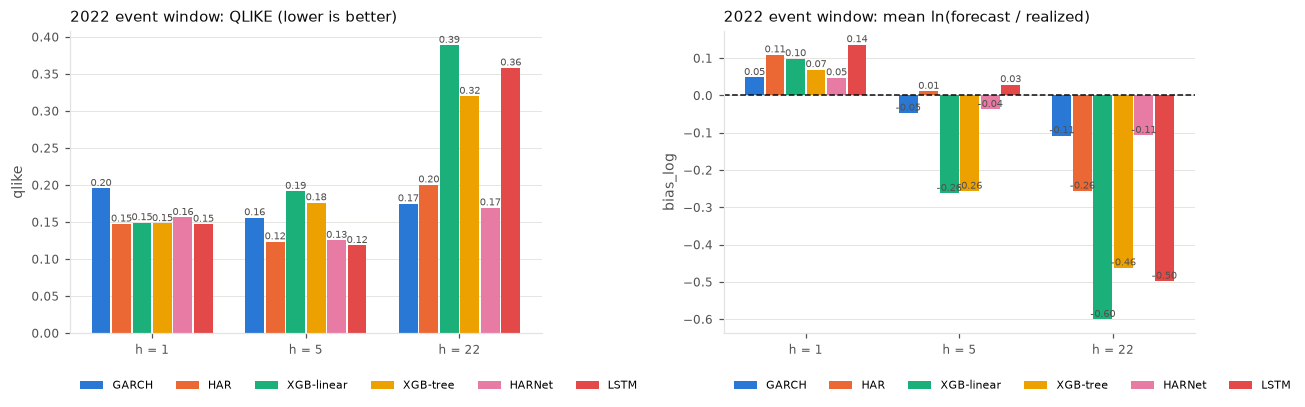

In [11]:
track = E.tracking_table(df, "bear2022")
track.to_csv(out_dir / "bear2022_tracking.csv", index=False)
display(track[track["fs"].isin(["ext", "-"])].sort_values(["h", "qlike"]).set_index(["h", "family"])
        .drop(columns=["fs"]).style.format("{:.3f}"))
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
P.bar_by_family(track, "qlike", ax=axes[0], title="2022 event window: QLIKE (lower is better)")
P.bar_by_family(track, "bias_log", ax=axes[1], ref=0.0, title="2022 event window: mean ln(forecast / realized)")
fig.tight_layout(); fig.savefig(out_dir / "bear2022_tracking.png", dpi=150)

## 5. Accurate, or just alarm-happy?

A model can look like a great early-warning system simply because it forecasts high variance often.
Three checks separate the two:

1. **Alarm skill** (hit rate vs false-alarm rate over *all* out-of-sample days). The diagonal is no skill:
   an always-alarm model sits at (1, 1). **Peirce = hit − false alarm** is the distance above it.
2. **Alarm-to-stress ratio**: how often the model alarms relative to how often stress actually occurred
   (≈ 1 calibrated, > 1 alarm-happy).
3. **Calm-window bias**: mean ln(forecast/realized) when nothing is happening. Above 0 = over-forecasts in calm markets.

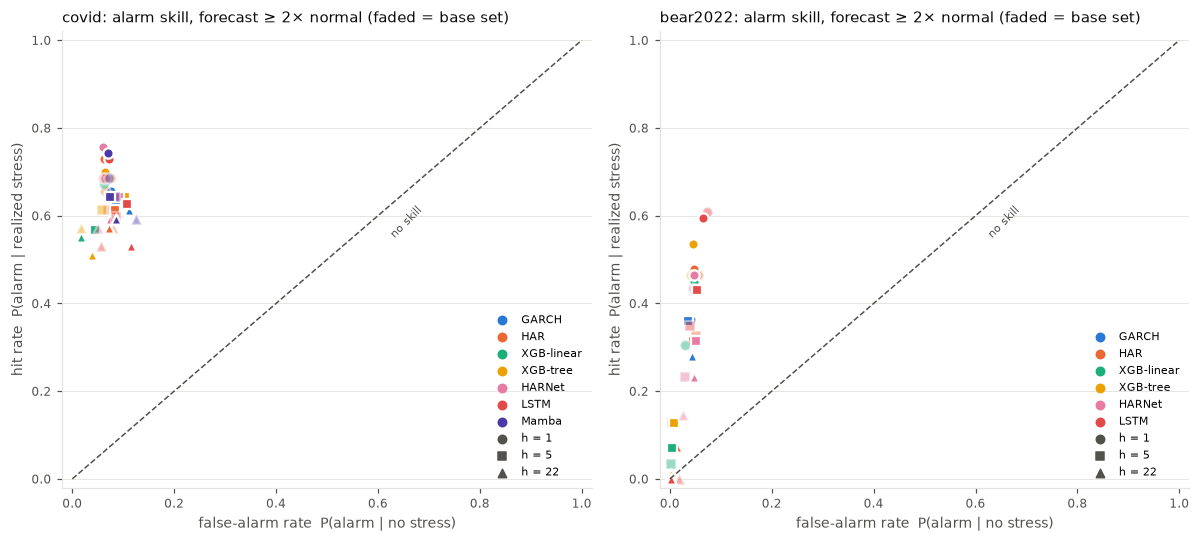

In [12]:
alarms = E.alarm_table(df)
alarms.to_csv(out_dir / "alarm_skill.csv", index=False)
fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, event in zip(axes, ("covid", "bear2022")):
    P.plot_alarm_skill(alarms, event, tau=2.0, ax=ax)
fig.tight_layout(); fig.savefig(out_dir / "alarm_skill.png", dpi=150)

In [13]:
a = alarms[(alarms["tau"] == 2.0) & alarms["fs"].isin(["ext", "-"])]
show = ["hit_rate", "false_alarm_rate", "peirce", "alarm_to_stress", "calm_false_alarm_rate", "calm_bias_log"]
for event in ("covid", "bear2022"):
    t = a[a["event"] == event].set_index(["h", "family"])[show].sort_index()
    display(t.style.format("{:.2f}").background_gradient(subset=["peirce"], cmap="Greens")
            .set_caption(f"{event}: alarm diagnostics at forecast ≥ 2× normal (ext set)"))

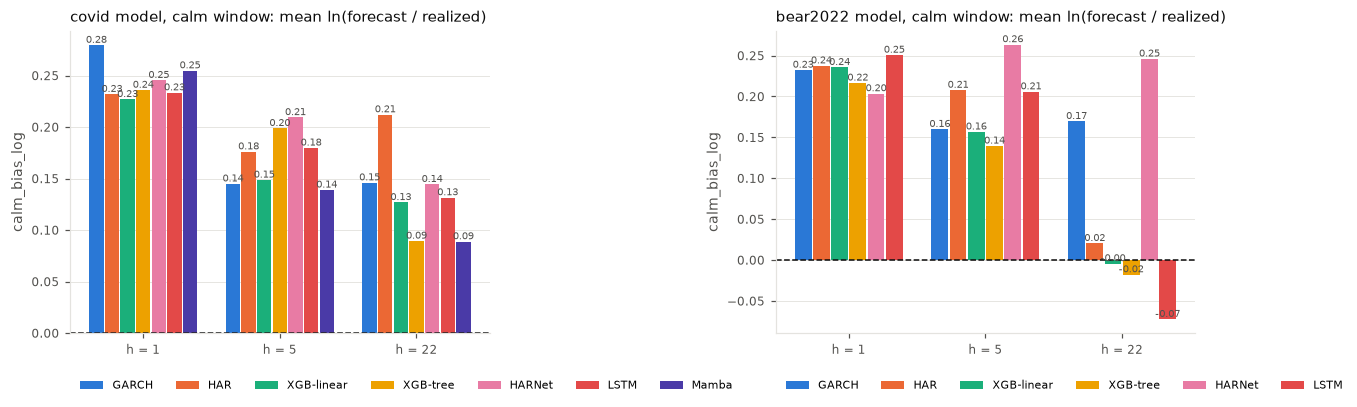

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, event in zip(axes, ("covid", "bear2022")):
    t = a[a["event"] == event]
    P.bar_by_family(t, "calm_bias_log", ax=ax, ref=0.0, title=f"{event} model, calm window: mean ln(forecast / realized)")
fig.tight_layout(); fig.savefig(out_dir / "calm_bias.png", dpi=150)

### Is the event-window advantage statistically significant?

Diebold–Mariano tests on QLIKE against the HAR (base) benchmark, event window, with a Newey–West variance (lag h − 1).
A negative statistic means the model's loss is lower than HAR's.

In [15]:
dm = E.dm_vs_benchmark(df, "HAR", segments=("event",))
dm.to_csv(out_dir / "dm_event_vs_har.csv", index=False)
d = dm[dm["fs"].isin(["ext", "-"])].pivot_table(index="family", columns=["event", "h"], values=["dm_stat", "p_value"])
display(d.style.format("{:.2f}"))

## 7. Methodological finding: an unseen crash in the validation block inflates the smearing factor

The log-target models (HAR, XGBoost, LSTM, Mamba) are converted back to variance with Duan's smearing factor
S = mean(exp(validation residual)) of the **train-only** model. Originally the 2022 validation block was the last 10% of
pre-cutoff days (2019-12-23 → 2021-09-30). **It contained COVID, but the train-only models were trained only through 2019.**
They badly under-predicted March 2020, their residuals were huge, and S inflated to ≈ 2.2 at h = 22. The refit models,
which *had* seen COVID, inherited that factor, so every 2022 forecast was multiplied by ≈ 2.2.

**Fix (now the main specification):** the 2022 models train through 2020-12-31 and validate on 2021-01-04 → 2021-09-30.
The cutoff and the forecasts are unchanged in design. The old run is archived in `data/processed/archive/val_with_covid/`.
Validating on post-2023 data was rejected: that would be look-ahead, and it overlaps the calm window used for false alarms.

Grey bars = old split (validation with COVID); colored = new split. HARNet has no smearing (S = 1). For GARCH the column shows its fixed RV-scale factor c, not a smearing factor.

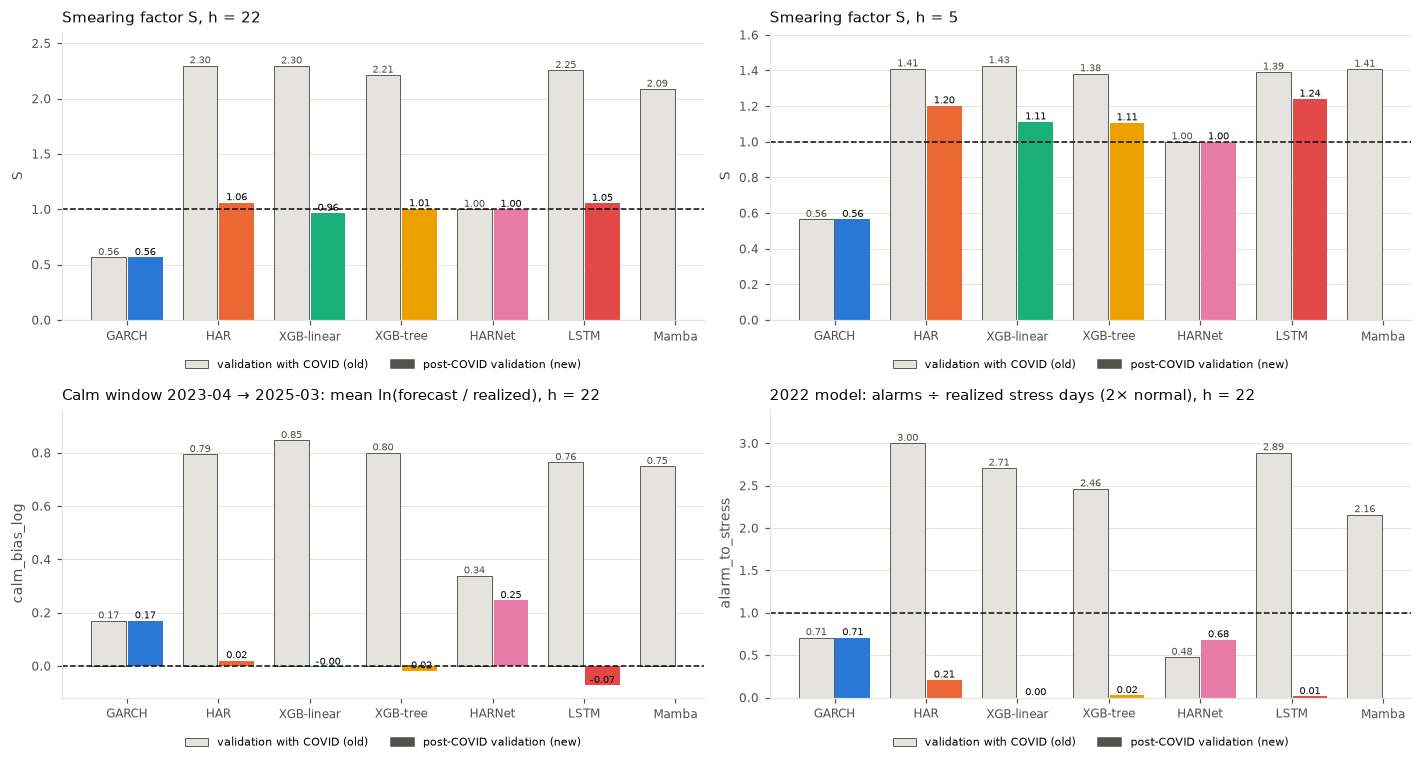

In [16]:
comp = E.smearing_comparison(PROJECT_ROOT / "data/processed/archive/val_with_covid/forecasts",
                             resolve_path(cfg["paths"]["forecasts_dir"]), features=features)
comp.to_csv(out_dir / "smearing_finding_2022.csv", index=False)
fig, axes = plt.subplots(2, 2, figsize=(13, 7))
P.plot_smearing_shift(comp, "S", 22, ax=axes[0, 0], ref=1.0, title="Smearing factor S, h = 22")
P.plot_smearing_shift(comp, "S", 5, ax=axes[0, 1], ref=1.0, title="Smearing factor S, h = 5")
P.plot_smearing_shift(comp, "calm_bias_log", 22, ax=axes[1, 0], ref=0.0,
                      title="Calm window 2023-04 → 2025-03: mean ln(forecast / realized), h = 22")
P.plot_smearing_shift(comp, "alarm_to_stress", 22, ax=axes[1, 1], ref=1.0,
                      title="2022 model: alarms ÷ realized stress days (2× normal), h = 22")
fig.tight_layout(); fig.savefig(out_dir / "smearing_finding_2022.png", dpi=150)

In [17]:
cols = ["S", "event_qlike", "event_bias_log", "calm_bias_log", "alarm_to_stress", "peirce", "lead_days_2.0x"]
show = comp[comp["fs"].isin(["ext", "-"])].set_index(["h", "family"]).sort_index()
show = show[[f"{c}__{s}" for c in cols for s in ("val_with_covid", "val_post_covid")]]
show.columns = pd.MultiIndex.from_tuples([tuple(c.split("__")) for c in show.columns])
display(show.style.format("{:.2f}", na_rep="–").set_caption("2022 event, ext set: old split vs new split"))

## 8. Summary of findings

Numbers are for the `ext` feature set unless noted. "Normal" = the long-run training-sample RV (≈ 14–15% annualized vol).
The 2022 models use the corrected split (trained through 2020, validated on 2021-01 → 2021-09; §7).
**The Mamba 2022 cells are pending a re-run on that split**, so Mamba appears only in the COVID results for now.

### Q1. COVID-19: who warned, and who said "it will continue"?

- **No model gave a real warning before the 19 Feb peak.** Every model first crossed 1.5× normal on 24–28 Feb, after the
  peak. GARCH was first (24 Feb), and the h = 22 LSTM and XGBoost were last.
- **After the first drop, HARNet was the model that said "this will get worse".** Over the first 10 event days at h = 5:
  - HARNet's forecasts stood 1.28× above the last week's realized level (escalation), against 0.92–1.09 for every other
    model including Mamba.
  - It anticipated 52% of the variance that followed (coverage), against 30–38% for the rest.
  - It beats HAR on event QLIKE at h = 5 (DM p = 0.013).
  - Mamba ranks second on escalation (1.33 at h = 1, 1.09 at h = 5), ahead of the LSTM (1.15 / 0.99).
- **At h = 22 every model badly under-forecast the crash** (coverage ≤ 17%). The bounded-output models were worst:
  - LSTM ceiling: 47–50% vol, exceeded on 17–18 of 23 event days.
  - Mamba ceiling: 37–41% vol, exceeded on 20–22 days.
  - Tree ceiling: ≈ 26% vol.

  The level models GARCH and HARNet reached 80% and 71% vol, but only with a lag.

### Q2. 2022 bear market: who tracked the slow decline?

- **Warning before the 3 Jan 2022 peak.** At h = 1 and 5, HARNet, the LSTM and XGB-tree crossed 2× normal on
  1–3 Dec 2021, about 20 trading days before the peak, after the Omicron spike. At h = 22 only HARNet rose early (1.5× on
  1 Dec). GARCH stayed below 2× until March 2022.
- **Over the nine-month decline, the level models tracked best at the monthly horizon.** At h = 22, against a realized
  mean of 19.1% vol:
  - HARNet averaged 18.5% (QLIKE 0.169) and GARCH 18.4% (0.175).
  - The log-target models stayed near *normal*: HAR 16.7%, XGB-tree 15.1%, LSTM 14.8%, XGB-linear 13.9%.
    XGBoost and LSTM are significantly worse than HAR (DM p ≤ 0.038).
  - At h = 1 and 5 the models are close; the LSTM is best (QLIKE 0.147 / 0.118).

### Q3. Accurate, or alarm-happy?

- **COVID: HARNet's edge is genuine.** It has the best alarm skill at h = 1 (Peirce 0.70 at 2× normal) and raises alarms
  about as often as stress occurs (alarm-to-stress 1.07–1.18).
- **2022, corrected split: no model is alarm-happy any more.** Calm-window bias at h = 22 is about 0 for the log models
  (−0.07 to +0.02) and +0.17 / +0.25 for GARCH / HARNet. The models that alarm well at h = 1 (LSTM Peirce 0.53, XGB-tree
  0.49) do so with a 4–6% false-alarm rate. At h = 22, however, the log models *under-warn*: they almost never reach 2×
  normal during 2022 (alarm-to-stress ≤ 0.21), so their alarm skill is about 0. HARNet and GARCH keep modest skill
  (0.19 / 0.24).
- **Before the correction, the opposite looked true.** With the COVID-contaminated smearing factor (S ≈ 2.2), the same
  log models looked like the best 2022 trackers and earliest warners. That was a uniform ≈ 2.2× over-forecast, visible as
  a +0.8 log bias in the calm window afterwards (§7). The same h = 22 QLIKE can come from opposite errors: HAR scores
  0.19 inflated and 0.20 corrected, with bias +0.52 vs −0.26.

### What this means for the thesis

1. **Fast crash:** none of these models predicts a crash from a calm market. What separates them is how fast and how far
   they react after the first drop. Level-trained models (HARNet, GARCH) react most. Bounded models (trees, LSTM, Mamba)
   are structurally capped at long horizons.
2. **Slow decline:** level models track a persistent high-volatility regime best at the monthly horizon. Log-target
   models mean-revert too strongly at h = 22.
3. **Methodological:**
   - A retransformation (smearing) factor estimated on a validation block that contains a shock unseen in training
     inflates every forecast. That inflation can masquerade as early-warning skill.
   - The fix (shock inside training) has its own caveat: validating on a calm 2021 favors models that expect calm. Report
     both splits; the notebook's §7 table does this.
4. **Long memory:** Mamba improves on the LSTM in the COVID onset but does not beat HARNet. In 2022 the LSTM now picks a
   126-day lookback in 4 of 6 cells, so long memory matters more once COVID is in training. Mamba's 2022 re-run will test
   whether selectivity helps there.
5. **Pending:** Mamba 2022 re-run (GPU); XGBoost `wide` robustness (the tree ceiling); model confidence set.